Order of Events
1. Planning
    - Get coordinates of environment (from Vision)
    - Compute visibility graph and path (from Global Nav)
3. Motion
    - Start following path
    - Continuously correct route with Kalman filter (from Kalman)
4. Local Navigation
    - Add extra obstacle in path
    - Avoid obstacle (from Local Nav)
5. Success
    - Reach Goal

In [1]:
import numpy as np 
import matplotlib.pyplot as plt
from tdmclient import ClientAsync, aw
import math
from VisibilityGraph import *
from kalman_filter import *
from Vision import *

In [2]:
client = ClientAsync()
node = aw(client.wait_for_node())
await node.lock()

Node eeecc8f0-055d-414f-a168-42c3ba3a5cd9

In [3]:
# Global Nav Variables as standin for input from Vision

ob1 = [(176, 206), (215, 217), (194, 294), (155, 283)]
ob2 = [(522, 440), (562, 440), (562, 520), (522, 520)]
ob3 = [(870, 267), (909, 256), (930, 333), (891, 344)]

raw_obstacles = (ob1, ob2, ob3)

In [4]:
path, coords = run_global_nav(start, goal, raw_obstacles)
print(path, coords)

NameError: name 'start' is not defined

In [5]:
# def compute_heading(a, b, prev_heading):
#     distance = np.linalg.norm(a - b, ord=2)
    
#     dx = b[0] - a[0]
#     dy = b[1] - a[1]
#     heading = math.atan(dy/dx) - prev_heading
#     prev_heading = math.atan(dy/dx)

#     return distance, heading, prev_heading

In [6]:
def wrap_angle(angle):
    """Wrap angle to [-pi, pi]."""
    return math.atan2(math.sin(angle), math.cos(angle))

def compute_heading(a, b, prev_heading):
    dx = b[0] - a[0]
    dy = b[1] - a[1]

    distance = math.hypot(dx, dy)
    abs_heading = math.atan2(dy, dx)          # absolute heading of this segment
    turn = wrap_angle(abs_heading - prev_heading)  # signed turn needed from current heading

    return distance, turn, abs_heading

In [7]:
SPEED_TO_MM_S = 0.335   
WHEEL_BASE = 95.0

async def set_speed(left, right):
    await node.set_variables({
        "motor.left.target": [int(left)],
        "motor.right.target": [int(right)]
    })
    
async def forward(v, d): # [mm/s, mm]
    T = d/v
    thymio_v = v/SPEED_TO_MM_S
    
    try:
        await set_speed(thymio_v, thymio_v)
        await client.sleep(T)          
    finally:
        await set_speed(0, 0)
        
async def turn(v, theta): # [rad/s, rad]

    arc = abs(theta) * WHEEL_BASE / 2 
    T = arc / v                          
    thymio_v =  abs(v) / SPEED_TO_MM_S         
    direction = 1 if theta > 0 else -1
    try:
        await set_speed(-direction * thymio_v, direction * thymio_v)
        await client.sleep(T)
    finally:
        await set_speed(0, 0)

In [8]:
get_current_thymio_pose()

2026-11-24 17:07:01.530 Python[24670:7815013] WARNING: AVCaptureDeviceTypeExternal is deprecated for Continuity Cameras. Please use AVCaptureDeviceTypeContinuityCamera and add NSCameraUseContinuityCameraDeviceType to your Info.plist.


NameError: name 'H_mm' is not defined

In [26]:
v = 100
prev_heading = get_current_thymio_pose()[2]

for i in range(len(path)-1):
    distance, heading, prev_heading = compute_heading(coords[i], coords[i+1], prev_heading)
    print(distance, heading, prev_heading)
    await turn(v, heading)
    await forward(v, distance)




TypeError: 'int' object is not subscriptable

In [ ]:
await forward(100, 10)

In [26]:
await turn(100, np.pi)

Obstacles detected: 2


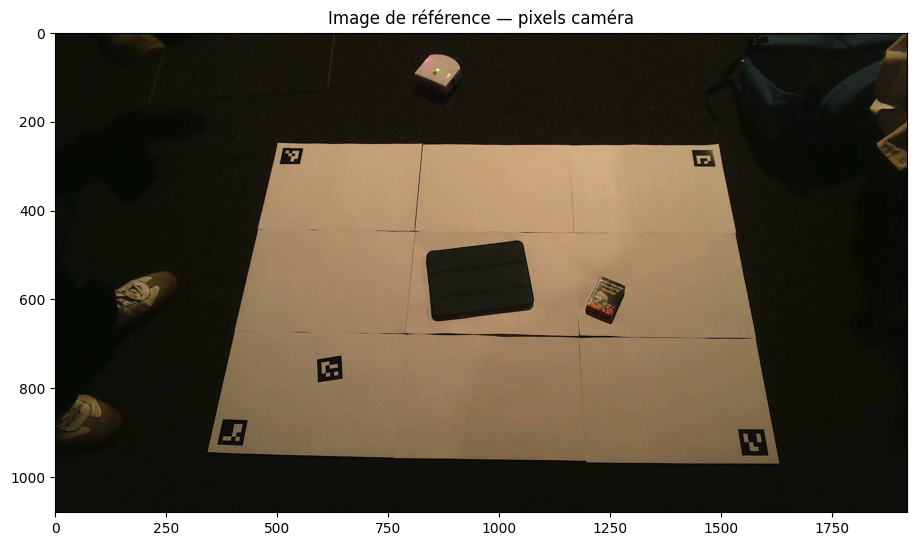

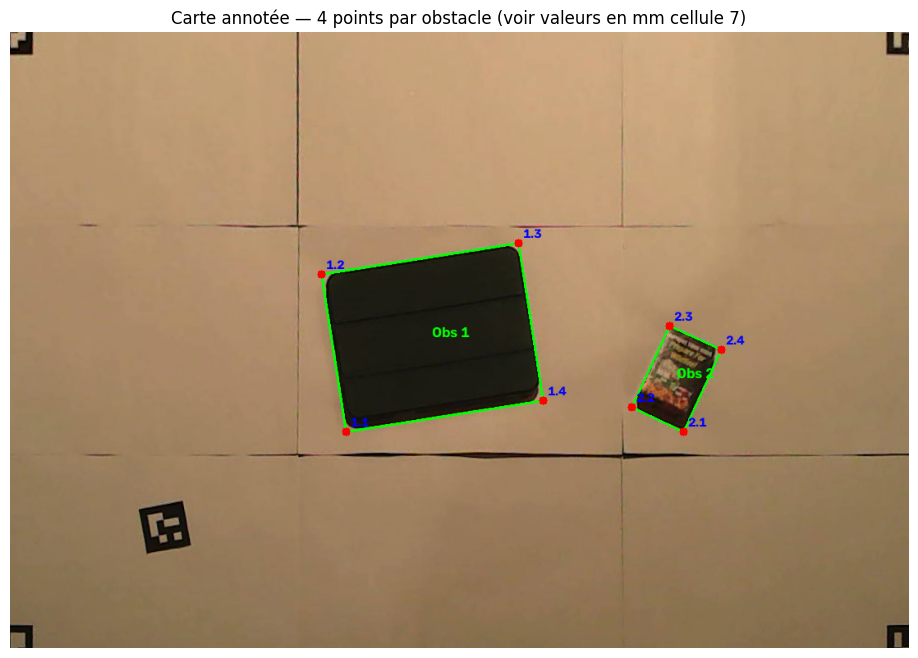

Image enregistrée : /Users/nataliedellimmagine/Documents/EPFL Semester 1/Mobile Robotics/mobile_robotics/navigation_annotated.png


In [22]:
initialize_vision(True)

In [23]:
get_obstacles_pose()

[2,
 [(409.57, 263.75), (379.76, 456.11), (619.92, 493.36), (649.73, 301.0)],
 [(820.92, 263.76), (757.73, 293.05), (804.03, 393.0), (867.21, 363.7)]]

In [24]:
raw_obstacles = get_obstacles_pose()[1:]


In [25]:
raw_obstacles

[[(409.57, 263.75), (379.76, 456.11), (619.92, 493.36), (649.73, 301.0)],
 [(820.92, 263.76), (757.73, 293.05), (804.03, 393.0), (867.21, 363.7)]]

(175.8, 160.81)
(1000, 700)
[0, 3, 1] [array([175.8 , 160.81]), array([308.75649083, 507.72183572]), array([1000.,  700.])]


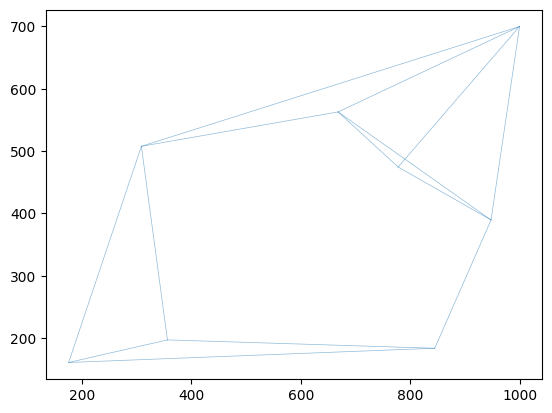

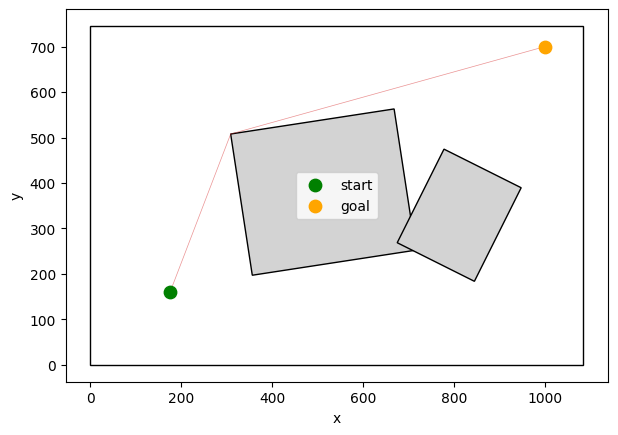

In [20]:
start = tuple(get_current_thymio_pose()[:2])
print(start)
goal = (1000, 700)
print(goal)

path, coords = run_global_nav(start, goal, raw_obstacles)
print(path, coords)

In [7]:
print(get_current_thymio_pose())


[490.57, 373.66, 0.71]
